## Problem definition
Biologists need a simple and automated way to correctly identify iris flower species without relying on manual guesswork.
While some iris flowers look very different, others look almost identical. This project uses machine learning to look at four basic measurements, the length and width of the petals and sepals, to instantly predict the correct species (Setosa, Versicolor, or Virginica).

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import joblib

### Load the Dataset

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
X, y = iris.data, iris.target

print(iris.feature_names)
print(iris.target_names)

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


### Exploratory Data Analysis

In [23]:
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = [iris.target_names[i] for i in iris.target]

# Set a clean visual theme for all plots
sns.set_theme(style="whitegrid")

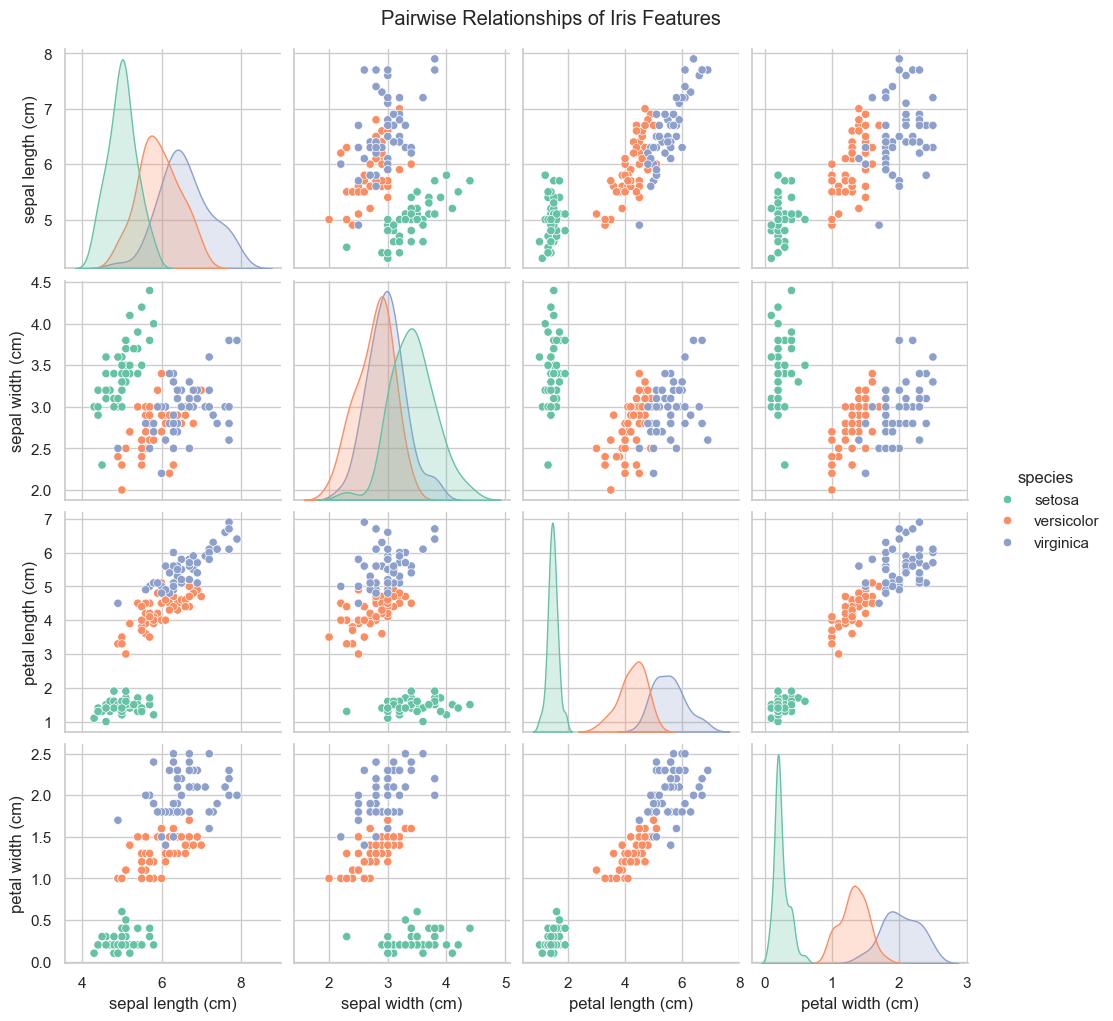

In [24]:
sns.pairplot(df, hue="species", palette="Set2", diag_kind="kde")
plt.suptitle("Pairwise Relationships of Iris Features", y=1.02)
plt.show()

### Prepocessing

In [3]:
# Split the Data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.2, random_state=1
)

In [4]:
X_train[:10]

array([[6.1, 3. , 4.6, 1.4],
       [7.7, 3. , 6.1, 2.3],
       [5.6, 2.5, 3.9, 1.1],
       [6.4, 2.8, 5.6, 2.1],
       [5.8, 2.8, 5.1, 2.4],
       [5.3, 3.7, 1.5, 0.2],
       [5.5, 2.3, 4. , 1.3],
       [5.2, 3.4, 1.4, 0.2],
       [6.5, 2.8, 4.6, 1.5],
       [6.7, 2.5, 5.8, 1.8]])

In [5]:
y_train[:10]

array([1, 2, 1, 2, 2, 0, 1, 0, 1, 2])

In [6]:
for i, value in enumerate(iris.target_names):
    print(i, value)

0 setosa
1 versicolor
2 virginica


#### Feature scaling and model training pipeline

In [8]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', DecisionTreeClassifier(max_depth=3, random_state=42))
])

pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2


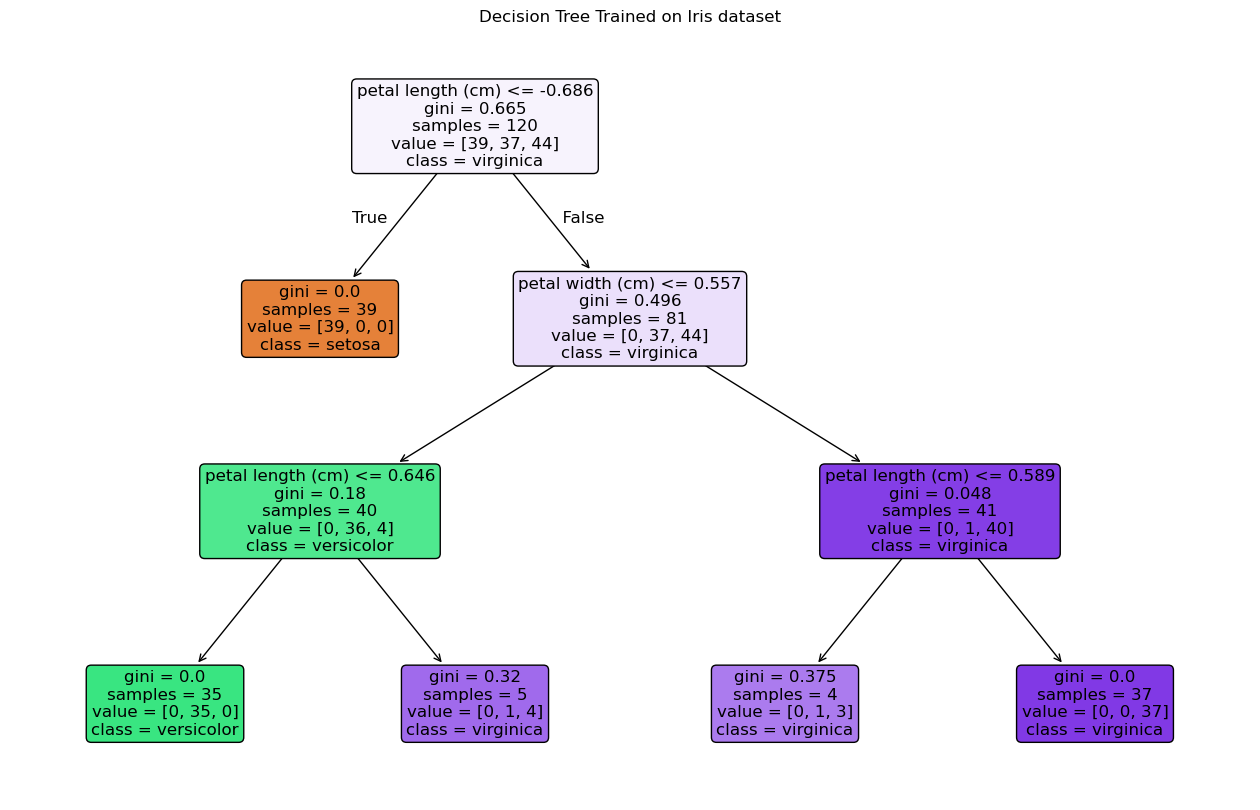

In [11]:
plt.figure(figsize=(16, 10))

#tree_model = pipeline.named_steps['model']

plot_tree(
    pipeline[-1], 
    feature_names=iris.feature_names,
    class_names=["setosa", "versicolor", "virginica"],
    filled=True, 
    rounded=True,
    fontsize=12,
)

plt.title("Decision Tree Trained on Iris dataset")
plt.show()

#### Model prediction

In [13]:
y_pred = pipeline.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9666666666666667


In [14]:
print(y_pred)
print(y_test)

[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 2 0 2 1 0 0 1 2]
[0 1 1 0 2 1 2 0 0 2 1 0 2 1 1 0 1 1 0 0 1 1 1 0 2 1 0 0 1 2]


In [15]:
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      0.92      0.96        13
           2       0.86      1.00      0.92         6

    accuracy                           0.97        30
   macro avg       0.95      0.97      0.96        30
weighted avg       0.97      0.97      0.97        30



In [16]:
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))


Confusion Matrix:
 [[11  0  0]
 [ 0 12  1]
 [ 0  0  6]]


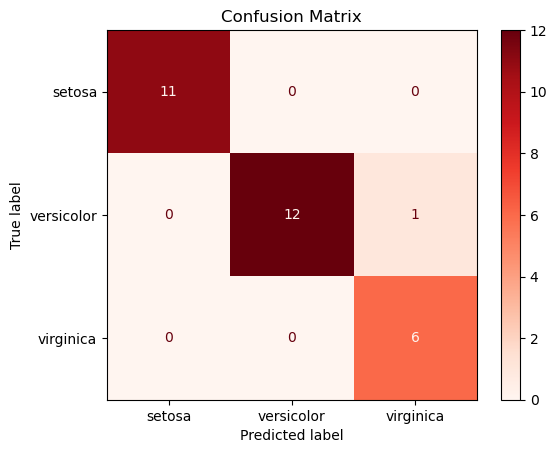

In [18]:
import matplotlib.pyplot as plt

cm_display = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=iris.target_names)
cm_display.plot(cmap=plt.cm.Reds)
plt.title('Confusion Matrix')
# plt.colorbar()
plt.show()

#### Prediction function

In [20]:
def predict_flower(sepal_length, sepal_width, petal_length, petal_width):
    
    sample = [[sepal_length, sepal_width, petal_length, petal_width]]
    
    # Predict
    pred = pipeline.predict(sample)[0]
    species = iris.target_names
    prediction = f'The specie of flower is {species[pred]}'
    
    return prediction

In [21]:
print(predict_flower(5.1, 3.5, 1.4, 0.2))

The specie of flower is setosa


In [22]:
print(predict_flower(6.0, 3.0, 4.8, 1.8))

The specie of flower is virginica


#### Model deployment and persistence

In [28]:
joblib.dump(pipeline, 'randomFIris_pipeline.joblib')

['randomFIris_pipeline.joblib']

In [27]:
joblib.dump(pipeline[-1], 'randomFIris_model.joblib')

['randomFIris_model.joblib']